# NB08 — Techno-economic and VPP analysis (2023)

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Turn the Notebook 6 & 7 results into the answers the brief asks for: bills, self-consumption, export revenue, savings and payback for
each tariff; whether the $25/month VPP service is worth it for the **customer**; what the **retailer/VPP operator** gains; and how sensitive is the result.

**Scenarios used throughout**

| Scenario | Meaning | Source |
|---|---|---|
| S0 | No PV, no battery | Notebook 2 |
| S1 | PV only | Notebook 6 |
| S2 | PV + battery, self-consumption (default mode) | Notebook 6 |
| S3 | PV + battery, cost-optimised, perfect foresight (R1) | Notebook 6 |
| **S4** | PV + battery, cost-optimised **with forecasts** — the realistic case: R2 (PV forecast) for flat/ToU, R4 (PV forecast + pre-dispatch) for wholesale | Notebook 7 |

**Economics (Notes D.4.7):** installed cost of 13.5 kWh = $3,190 + $759/kWh × 13.5 = $13,437 after the Cheaper Home Batteries rebate
(linear fit to the Solar Choice index, Notebook 5); ±20 % cost range; simple payback = cost ÷ annual saving; warranty 10 years.
The $300/yr VPP fee is charged in every wholesale battery scenario (the battery is operated by the VPP), not in S1.

**Inputs:** `outputs/nb01_clean_2022_2023.csv`, `nb02_bills_S0_S1.csv`, `nb03_pv_forecast_2023_hourly.csv`, `nb04_pd_forecast_wide_2023.csv`,
`nb06_results_2023.csv`, `nb07_results_2023.csv`, Notebook 6/7 dispatch files, `bess_functions.py`.
**Outputs:** `outputs/nb08_master_table.csv`, `nb08_economics.csv`, `nb08_customer_options.csv`, `nb08_retailer_view.csv`,
`nb08_sensitivities.csv`, `nb08_exec_summary.csv`; figures fig11a–fig11d. **Run order:** last.

## Cell 0 — Settings

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(os.path.join(BASE_DIR, 'bess_functions.py')), 'Upload bess_functions.py to ' + BASE_DIR
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports, data and the master table (scenario × tariff)

In [2]:
# Cell 1 - imports, data, master table
import time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bess_functions as bf
importlib.reload(bf)

DT_H = 5 / 60
VPP_FEE_AUD = 300.0
E_CAP = bf.BATTERY['e_cap_kwh']
COST_AUD = 3190 + 759 * E_CAP                  # installed cost after rebate, linear fit (NB05) [R24, R25]
WARRANTY_YR = 10                               # [R22]
TARIFFS = {'flat': ('import_flat_aud_kwh', 'export_flat_aud_kwh'),
           'tou': ('import_tou_aud_kwh', 'export_tou_aud_kwh'),
           'wholesale': ('import_wholesale_aud_kwh', 'export_wholesale_aud_kwh')}
S4_RUN = {'flat': 'R2', 'tou': 'R2', 'wholesale': 'R4'}
COL_T = {'flat': '#4c72b0', 'tou': '#55a868', 'wholesale': '#c44e52'}
COL_S = {'S0': '#bfbfbf', 'S1': '#f2a900', 'S2': '#8fb3d9', 'S3': '#1f4e79', 'S4': '#55a868'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime']).set_index('datetime')
y23 = df.loc['2023-01-01 00:05':'2023-12-31 23:55']
nb06 = pd.read_csv(os.path.join(OUT_DIR, 'nb06_results_2023.csv'))
nb07 = pd.read_csv(os.path.join(OUT_DIR, 'nb07_results_2023.csv'))

def dispatch(tariff, scen):
    # 5-min results saved by NB06 (S1-S3) or NB07 (forecast runs)
    f = f'nb06_dispatch_{tariff}_{scen}.csv.gz' if scen in ('S1', 'S2', 'S3') else f'nb07_dispatch_{tariff}_{scen}.csv.gz'
    return pd.read_csv(os.path.join(OUT_DIR, f), parse_dates=['datetime'], index_col='datetime')

cols = ['tariff', 'bill_aud', 'energy_cost_aud', 'import_kwh', 'export_kwh', 'export_revenue_aud', 'battery_export_kwh',
        'curtailed_kwh', 'self_consumption', 'self_sufficiency', 'equivalent_full_cycles']
s4 = pd.concat([nb07[(nb07.tariff == t) & (nb07.run == r)] for t, r in S4_RUN.items()]).assign(scenario='S4')
master = pd.concat([nb06[cols + ['scenario']], s4[cols + ['scenario']]], ignore_index=True)
master = master.set_index(['tariff', 'scenario']).sort_index()
s1_bill = master.xs('S1', level='scenario')['bill_aud']
s0_bill = master.xs('S0', level='scenario')['bill_aud']
master['saving_vs_S1_aud'] = master['bill_aud'] - master.index.get_level_values('tariff').map(s1_bill).to_numpy()
master['saving_vs_S1_aud'] *= -1
master['saving_vs_S0_aud'] = master.index.get_level_values('tariff').map(s0_bill).to_numpy() - master['bill_aud']
print(master[['bill_aud', 'saving_vs_S0_aud', 'saving_vs_S1_aud', 'export_revenue_aud', 'self_consumption', 'self_sufficiency',
              'equivalent_full_cycles']].round(2))

                    bill_aud  saving_vs_S0_aud  saving_vs_S1_aud  export_revenue_aud  self_consumption  self_sufficiency  equivalent_full_cycles
tariff    scenario                                                                                                                              
flat      S0         3365.23              0.00          -2570.55                 NaN               NaN               NaN                     NaN
          S1          794.68           2570.55             -0.00              760.77              0.28              0.54                    0.00
          S2           87.38           3277.84            707.29              600.15              0.44              0.80                  214.30
          S3          106.83           3258.40            687.85              604.71              0.43              0.79                  208.37
          S4          104.23           3260.99            690.45              604.11              0.43              0.79          

## Cell 2 — Savings and payback
Two views of the saving from adding the battery:
1. **vs PV only on the same tariff**  — isolates the battery;
2. **vs the best PV-only tariff** (ToU, the cheapest without a battery) — what a customer who already picked the best tariff would actually gain.

Payback = $13,437 ÷ saving (also at ±20 % cost). A payback longer than the 10-year warranty means the battery is unlikely to pay for itself
(capacity fades to ~70 % by year 10, prices and tariffs change — simple payback ignores both).

In [3]:
# Cell 2 - economics
best_pv_only = s1_bill.min(); best_pv_tariff = s1_bill.idxmin()
rows = []
for (t, sc), r in master.iterrows():
    if sc in ('S0', 'S1'):
        continue
    for basis, base_bill in [('same tariff', s1_bill[t]), (f'best PV-only ({best_pv_tariff})', best_pv_only)]:
        sav = base_bill - r['bill_aud']
        rows.append({'tariff': t, 'scenario': sc, 'basis': basis, 'annual_saving_aud': sav,
                     'payback_yr': COST_AUD / sav if sav > 0 else np.inf,
                     'payback_low_cost_yr': 0.8 * COST_AUD / sav if sav > 0 else np.inf,
                     'payback_high_cost_yr': 1.2 * COST_AUD / sav if sav > 0 else np.inf,
                     'net_10yr_aud': WARRANTY_YR * sav - COST_AUD})
econ = pd.DataFrame(rows)
print(f'Installed cost: ${COST_AUD:,.0f} (±20 %: ${0.8 * COST_AUD:,.0f}-${1.2 * COST_AUD:,.0f})')
print(f'Best PV-only tariff: {best_pv_tariff} (${best_pv_only:,.0f}/yr)\n')
print(econ[econ.scenario.isin(['S2', 'S4'])].round(1).to_string(index=False))

Installed cost: $13,436 (±20 %: $10,749-$16,124)
Best PV-only tariff: tou ($618/yr)

   tariff scenario              basis  annual_saving_aud  payback_yr  payback_low_cost_yr  payback_high_cost_yr  net_10yr_aud
     flat       S2        same tariff              707.3        19.0                 15.2                  22.8       -6363.6
     flat       S2 best PV-only (tou)              531.1        25.3                 20.2                  30.4       -8126.0
     flat       S4        same tariff              690.4        19.5                 15.6                  23.4       -6532.0
     flat       S4 best PV-only (tou)              514.2        26.1                 20.9                  31.4       -8294.5
      tou       S2        same tariff              651.7        20.6                 16.5                  24.7       -6919.0
      tou       S2 best PV-only (tou)              651.7        20.6                 16.5                  24.7       -6919.0
      tou       S4        same ta

## Cell 3 — Customer view: is the VPP (wholesale + $300/yr) worth it?
Options a customer with PV and a new battery can choose (realistic operation S4, or the default self-consumption mode S2):
the VPP offer is **wholesale S4 incl. fee**. We also show what the VPP would deliver with better price forecasts (Notebook 7 R3n, R3cap) and with
perfect foresight (S3), and the **break-even fee** at which the VPP equals the best non-VPP option.

Best non-VPP option: ToU, optimised (S4) ($-73/yr)

                                        bill_aud_incl_fee  vs_best_non_vpp_aud  break_even_fee_aud_yr
Flat, self-consumption (S2)                          87.0                160.0                    NaN
Flat, optimised (S4)                                104.0                177.0                    NaN
ToU, self-consumption (S2)                          -33.0                 39.0                    NaN
ToU, optimised (S4)                                 -73.0                  0.0                    NaN
VPP: wholesale, pre-dispatch (S4)                   303.0                376.0                  -76.0
VPP: wholesale, naive prices (R3n)                  216.0                289.0                   11.0
VPP: wholesale, capped PD (R3cap)                   222.0                295.0                    5.0
VPP: wholesale, perfect foresight (S3)             -159.0                -86.0                  386.0


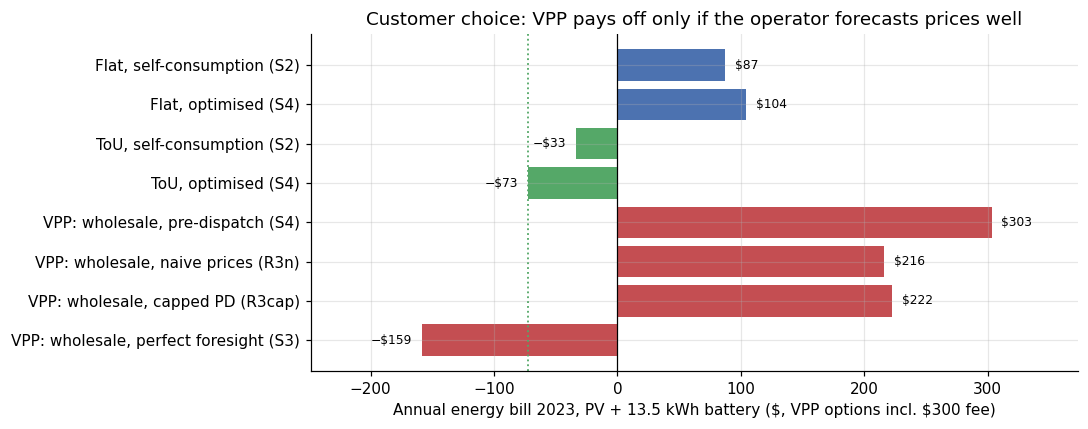

In [4]:
# Cell 3 - customer options
opt = {
    'Flat, self-consumption (S2)': master.loc[('flat', 'S2'), 'bill_aud'],
    'Flat, optimised (S4)': master.loc[('flat', 'S4'), 'bill_aud'],
    'ToU, self-consumption (S2)': master.loc[('tou', 'S2'), 'bill_aud'],
    'ToU, optimised (S4)': master.loc[('tou', 'S4'), 'bill_aud'],
    'VPP: wholesale, pre-dispatch (S4)': master.loc[('wholesale', 'S4'), 'bill_aud'],
    'VPP: wholesale, naive prices (R3n)': nb07.query("tariff=='wholesale' and run=='R3n'")['bill_aud'].iloc[0],
    'VPP: wholesale, capped PD (R3cap)': nb07.query("tariff=='wholesale' and run=='R3cap'")['bill_aud'].iloc[0],
    'VPP: wholesale, perfect foresight (S3)': master.loc[('wholesale', 'S3'), 'bill_aud'],
}
customer = pd.Series(opt, name='bill_aud_incl_fee').to_frame()
best_non_vpp = customer.loc[~customer.index.str.startswith('VPP')].bill_aud_incl_fee.min()
best_non_vpp_name = customer.loc[~customer.index.str.startswith('VPP')].bill_aud_incl_fee.idxmin()
customer['vs_best_non_vpp_aud'] = customer.bill_aud_incl_fee - best_non_vpp
customer['break_even_fee_aud_yr'] = np.where(customer.index.str.startswith('VPP'),
                                             VPP_FEE_AUD - customer.vs_best_non_vpp_aud, np.nan)
print(f'Best non-VPP option: {best_non_vpp_name} (${best_non_vpp:,.0f}/yr)\n')
print(customer.round(0))

fig, ax = plt.subplots(figsize=(10, 4))
cc = ['#4c72b0' if i.startswith('Flat') else '#55a868' if i.startswith('ToU') else '#c44e52' for i in customer.index]
ax.barh(customer.index[::-1], customer.bill_aud_incl_fee[::-1], color=cc[::-1])
for y_, v_ in enumerate(customer.bill_aud_incl_fee[::-1]):
    txt = f'\\${v_:,.0f}' if v_ >= 0 else f'−\\${-v_:,.0f}'          # \$ = literal dollar sign in matplotlib
    ax.text(v_ + (8 if v_ >= 0 else -8), y_, txt, va='center', ha='left' if v_ >= 0 else 'right', fontsize=8)
ax.set_xlim(customer.bill_aud_incl_fee.min() - 90, customer.bill_aud_incl_fee.max() + 70)
ax.axvline(0, color='k', lw=0.8); ax.axvline(best_non_vpp, color='#55a868', ls=':', lw=1.2)
ax.set_xlabel('Annual energy bill 2023, PV + 13.5 kWh battery (\\$, VPP options incl. \\$300 fee)')
ax.set_title('Customer choice: VPP pays off only if the operator forecasts prices well')
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig11b_customer_options.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 4 — Retailer / VPP-operator view
Per customer, ex GST, 2023:
- **Retailer energy margin** = revenue (import × tariff ÷ 1.1 − export × feed-in, + fee ÷ 1.1) − cost (import × (spot × 1.062 + network +
  0.01891) − export × spot), split into the import side and the export side (feed-in paid vs resale at spot). On ToU the retailer carries
  the wholesale risk; on wholesale passthrough the customer carries it and the retailer's margin is exactly the fee (checked below).
  Daily supply charges and retail costs are excluded (Notes Q8), so these are *energy* margins.
- **Grid value of the battery:** exports from the battery when the spot price > $300/MWh (spike support), energy and peak import in the
  network evening window 16:00–21:00 (Ergon peak), compared with PV only.

In [5]:
# Cell 4 - retailer / VPP view
def retailer_margin(res, fee=0.0):
    # retailer energy margin per interval ($, ex GST), split into the import side and the export side
    spot, net = y23['spot_aud_kwh'], y23['network_aud_kwh']
    m_imp = res.import_kw * (res.import_price / bf.GST - (spot * bf.LOSS_FACTOR + net + bf.ENV_MKT_AUD_KWH)) * DT_H
    m_exp = res.export_kw * (spot - res.export_price) * DT_H          # resale value at spot - feed-in paid
    return m_imp, m_exp, fee / bf.GST

cases = [('tou', 'S1'), ('tou', 'R2'), ('wholesale', 'S1'), ('wholesale', 'R4')]
evening = (y23.index - pd.Timedelta(minutes=5)).hour.isin(range(16, 21))
spike = y23.spot_aud_kwh > 0.300
rv = []
for t, sc in cases:
    r = dispatch(t, sc)
    fee = VPP_FEE_AUD if (t == 'wholesale' and sc != 'S1') else 0.0
    m_imp, m_exp, fee_ex = retailer_margin(r, fee)
    m = m_imp + m_exp
    bat_exp = np.minimum(r.export_kw, r.p_bat_kw.clip(lower=0))
    monthly = m.resample('MS').sum() + fee_ex / 12
    rv.append({'case': f'{t} {sc}', 'retailer_margin_aud': m.sum() + fee_ex, 'margin_on_imports_aud': m_imp.sum(),
               'margin_on_exports_aud': m_exp.sum(), 'fee_ex_gst_aud': fee_ex, 'margin_monthly_std_aud': monthly.std(),
               'worst_month_margin_aud': monthly.min(),
               'battery_export_in_spikes_kwh': bat_exp[spike].sum() * DT_H,
               'spike_export_value_aud': (bat_exp * y23.spot_aud_kwh)[spike].sum() * DT_H,
               'evening_import_kwh': r.import_kw[evening].sum() * DT_H,
               'evening_peak_import_kw': r.import_kw[evening].max(),
               'import_in_spikes_kwh': r.import_kw[spike].sum() * DT_H})
retail = pd.DataFrame(rv).set_index('case')
print(retail.round(1).T)
w = retail.loc['wholesale R4']
ew = (dispatch('tou', 'S1').export_kw * y23.spot_aud_kwh).sum() / dispatch('tou', 'S1').export_kw.sum()
print('\nExport-weighted spot price 2023: %.1f c/kWh vs 5 c/kWh feed-in -> every exported kWh costs a flat/ToU retailer money' % (100 * ew))
print('Note: daily supply charges and retail operating costs are excluded (Notes Q8), so these are energy margins only.')
print('\nCheck: wholesale passthrough margin = fee ex GST (%.2f vs %.2f)' % (w.retailer_margin_aud, VPP_FEE_AUD / bf.GST))
assert abs(w.retailer_margin_aud - VPP_FEE_AUD / bf.GST) < 1.0

case                          tou S1  tou R2  wholesale S1  wholesale R4
retailer_margin_aud           -405.6  -536.5          -0.0         272.7
margin_on_imports_aud            7.7   -93.9          -0.0          -0.0
margin_on_exports_aud         -413.4  -442.6          -0.0          -0.0
fee_ex_gst_aud                   0.0     0.0           0.0         272.7
margin_monthly_std_aud          38.3    33.8           0.0           0.0
worst_month_margin_aud        -110.6  -116.2          -0.0          22.7
battery_export_in_spikes_kwh     0.0     0.0           0.0         187.6
spike_export_value_aud           0.0     0.0           0.0         219.1
evening_import_kwh            1521.8   516.6        1521.8         442.2
evening_peak_import_kw           7.4     7.4           7.4           7.4
import_in_spikes_kwh           145.7   103.1         145.7          49.1

Export-weighted spot price 2023: 2.3 c/kWh vs 5 c/kWh feed-in -> every exported kWh costs a flat/ToU retailer money
Note: d

## Cell 5 — Sensitivities
Each changes one assumption and re-runs the realistic case S4 for ToU (R2) and wholesale (R4) — 6 runs — plus the timestamp shift on the
perfect-foresight case — 2 runs.
1. **Degradation cost $0.35/kWh** (= net battery cost ÷ warranted throughput, 13,110 ÷ 37,800 instead of $0.005/kWh — wear priced at
   replacement cost. The bill excludes this cost; the run shows how the operation changes.
2. **DC-coupled battery** — η = 0.97 each way (≈ 94 % round trip; upper part of the course paper's 95–98 % one-way range) instead of 0.949.
   No clipping exists to recover (Notebook 2), so efficiency is the only DC benefit modelled.
3. **Plan on P10 PV** (conservative forecast from Notebook 3) instead of the point forecast.
4. **PV 30 min earlier** — corrects the systematic ~30 min solar-noon offset found in Notebook 2 (data limitation): PV is moved 6 intervals earlier
   relative to load and prices; run with perfect foresight (S3) and compared with Notebook 6.

In [6]:
# Cell 5 - sensitivities
H = 48
hourly = df[['spot_aud_kwh', 'network_aud_kwh']].resample('h', label='right', closed='right').mean()
pvh = pd.read_csv(os.path.join(OUT_DIR, 'nb03_pv_forecast_2023_hourly.csv'), parse_dates=['datetime']).set_index('datetime')
pd_wide = pd.read_csv(os.path.join(OUT_DIR, 'nb04_pd_forecast_wide_2023.csv'), parse_dates=['plan_time']).set_index('plan_time')
PD_COLS = [f'h{h:02d}' for h in range(1, H + 1)]

def price_pd(t):                               # same as NB07 Cell 2
    spot = pd_wide.loc[t, PD_COLS].to_numpy(float)
    net = bf.window(hourly['network_aud_kwh'], t, H)
    return (spot * bf.LOSS_FACTOR + net + bf.ENV_MKT_AUD_KWH) * bf.GST, spot

pv_point = lambda t: bf.window(pvh['pv_forecast_kw'], t, H)
pv_p10 = lambda t: bf.window(pvh['pv_p10_kw'], t, H)
bat_deg = dict(bf.BATTERY, c_deg=0.35)
bat_dc = dict(bf.BATTERY, eta_ch=0.97, eta_dis=0.97)
y23_shift = y23.copy()
y23_shift['pv_actual_kw'] = df['pv_actual_kw'].shift(-6).reindex(y23.index).fillna(0.0)   # PV 30 min earlier

SENS = [  # (name, tariff, data, battery, pv_plan, price_plan)
    ('c_deg $0.35/kWh', 'tou', y23, bat_deg, pv_point, None), ('c_deg $0.35/kWh', 'wholesale', y23, bat_deg, pv_point, price_pd),
    ('DC-coupled η 0.97', 'tou', y23, bat_dc, pv_point, None), ('DC-coupled η 0.97', 'wholesale', y23, bat_dc, pv_point, price_pd),
    ('Plan on P10 PV', 'tou', y23, bf.BATTERY, pv_p10, None), ('Plan on P10 PV', 'wholesale', y23, bf.BATTERY, pv_p10, price_pd),
    ('PV 30 min earlier (S3)', 'tou', y23_shift, bf.BATTERY, None, None),
    ('PV 30 min earlier (S3)', 'wholesale', y23_shift, bf.BATTERY, None, None)]
rows = []
for name, t, data, bat, pvp, prp in SENS:
    ic, ec = TARIFFS[t]
    t0 = time.time()
    r = bf.run_operation(data, ic, ec, bat=bat, mode='cost', allow_curtail=(t == 'wholesale'), pv_plan=pvp, price_plan=prp)
    fee = VPP_FEE_AUD if t == 'wholesale' else 0.0
    st = bf.settle(r, bat=bat, fee_aud=fee)
    if name.startswith('PV 30'):
        base = master.loc[(t, 'S3'), 'bill_aud']
        s1_ref = bf.settle(bf.no_battery(data, ic, ec))['bill_aud']       # PV-only bill with the shifted PV
    else:
        base, s1_ref = master.loc[(t, 'S4'), 'bill_aud'], s1_bill[t]
    rows.append({'sensitivity': name, 'tariff': t, 'bill_aud': st['bill_aud'], 'base_bill_aud': base,
                 'change_vs_base_aud': st['bill_aud'] - base, 'saving_vs_S1_aud': s1_ref - st['bill_aud'],
                 'cycles': st['equivalent_full_cycles'], 'runtime_s': time.time() - t0})
    print(f'{name:24s} {t:9s} done in {time.time() - t0:.0f} s')
sens = pd.DataFrame(rows)
print(sens.round(1).to_string(index=False))

c_deg $0.35/kWh          tou       done in 95 s
c_deg $0.35/kWh          wholesale done in 100 s
DC-coupled η 0.97        tou       done in 104 s
DC-coupled η 0.97        wholesale done in 103 s
Plan on P10 PV           tou       done in 102 s
Plan on P10 PV           wholesale done in 103 s
PV 30 min earlier (S3)   tou       done in 100 s
PV 30 min earlier (S3)   wholesale done in 98 s
           sensitivity    tariff  bill_aud  base_bill_aud  change_vs_base_aud  saving_vs_S1_aud  cycles  runtime_s
       c_deg $0.35/kWh       tou     616.4          -72.7               689.1               2.0     0.4       94.9
       c_deg $0.35/kWh wholesale     644.9          303.2               341.7             378.4    63.7      100.1
     DC-coupled η 0.97       tou     -81.3          -72.7                -8.6             699.7   207.9      103.9
     DC-coupled η 0.97 wholesale     301.0          303.2                -2.2             722.3   190.3      102.6
        Plan on P10 PV       tou   

## Cell 6 — Final figures: annual bill by scenario and tariff, and payback

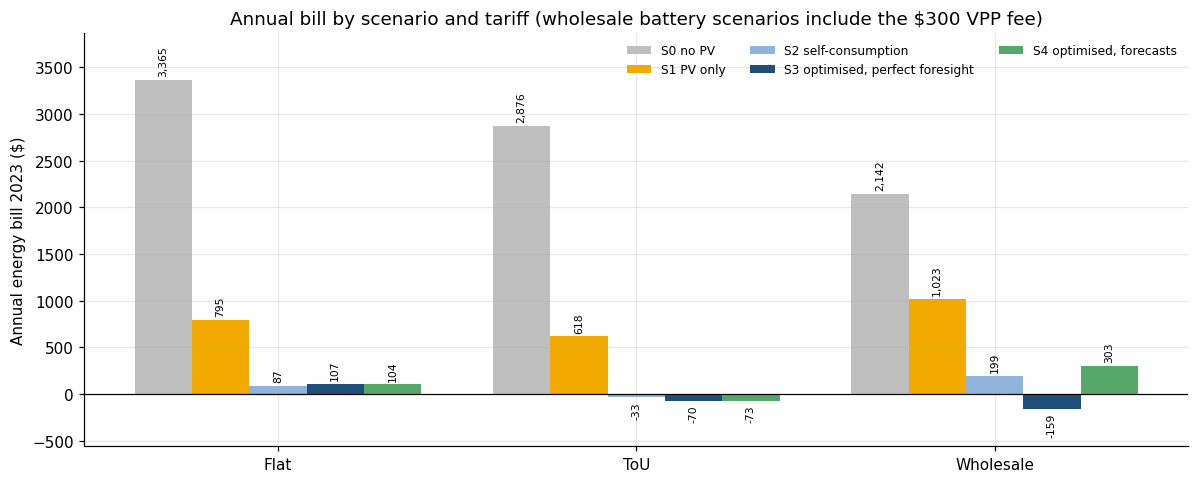

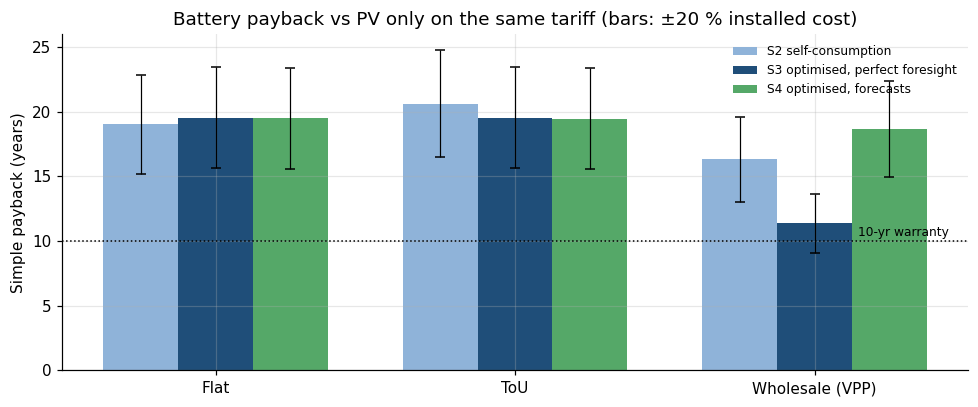

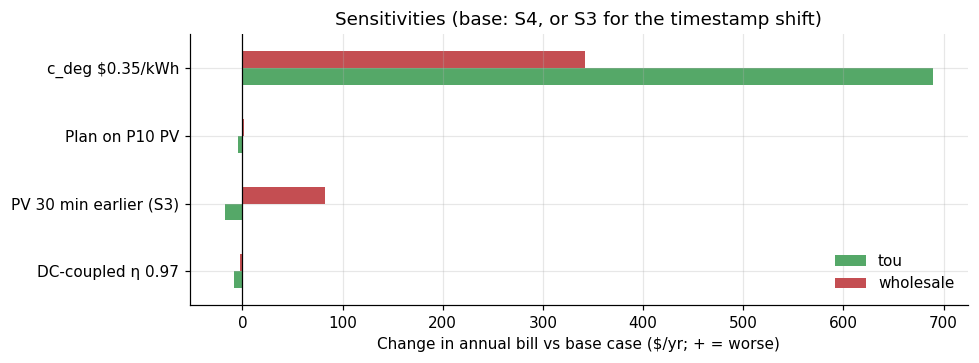

In [7]:
# Cell 6 - final figures
bills = master['bill_aud'].unstack('scenario')[['S0', 'S1', 'S2', 'S3', 'S4']]
labels = {'S0': 'S0 no PV', 'S1': 'S1 PV only', 'S2': 'S2 self-consumption', 'S3': 'S3 optimised, perfect foresight',
          'S4': 'S4 optimised, forecasts'}
fig, ax = plt.subplots(figsize=(11, 4.5))
xx = np.arange(len(bills)); w_ = 0.16
for k_, sc in enumerate(bills.columns):
    v = bills[sc]
    ax.bar(xx + (k_ - 2) * w_, v, w_, color=COL_S[sc], label=labels[sc])
    for x_, val in zip(xx + (k_ - 2) * w_, v):
        ax.text(x_, val + (40 if val >= 0 else -40), f'{val:,.0f}', ha='center', va='bottom' if val >= 0 else 'top', fontsize=7, rotation=90)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels([t.capitalize() if t != 'tou' else 'ToU' for t in bills.index])
ax.set_ylabel('Annual energy bill 2023 ($)'); ax.set_ylim(bills.min().min() - 400, bills.max().max() + 500)
ax.set_title('Annual bill by scenario and tariff (wholesale battery scenarios include the $300 VPP fee)')
ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper right')
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig11a_bills_by_scenario.png'), dpi=200, bbox_inches='tight'); plt.show()

e = econ[(econ.basis == 'same tariff') & econ.scenario.isin(['S2', 'S3', 'S4'])]
fig, ax = plt.subplots(figsize=(9, 3.8))
for k_, sc in enumerate(['S2', 'S3', 'S4']):
    d = e[e.scenario == sc].set_index('tariff').reindex(TARIFFS.keys())
    x_ = np.arange(3) + (k_ - 1) * 0.25
    ax.bar(x_, d.payback_yr.clip(upper=40), 0.25, color=COL_S[sc], label=labels[sc])
    ax.errorbar(x_, d.payback_yr.clip(upper=40), yerr=[(d.payback_yr - d.payback_low_cost_yr).clip(upper=40),
                (d.payback_high_cost_yr - d.payback_yr).clip(upper=40)], fmt='none', ecolor='k', lw=0.8, capsize=3)
ax.axhline(WARRANTY_YR, color='k', ls=':', lw=1); ax.text(2.45, WARRANTY_YR + 0.4, '10-yr warranty', ha='right', fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(['Flat', 'ToU', 'Wholesale (VPP)'])
ax.set_ylabel('Simple payback (years)'); ax.set_title('Battery payback vs PV only on the same tariff (bars: ±20 % installed cost)')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig11c_payback.png'), dpi=200, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
sp = sens.pivot(index='sensitivity', columns='tariff', values='change_vs_base_aud')
sp.plot.barh(ax=ax, color=[COL_T[c] for c in sp.columns])
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('Change in annual bill vs base case ($/yr; + = worse)')
ax.set_ylabel(''); ax.set_title('Sensitivities (base: S4, or S3 for the timestamp shift)'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig11d_sensitivities.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 7 — Executive-summary numbers (every number in the summary comes from here)

In [8]:
# Cell 7 - executive summary numbers
g = lambda t, s, c='bill_aud': master.loc[(t, s), c]
ex = {
    'Annual load (kWh)': y23.load_kw.sum() * DT_H,
    'Annual PV (kWh)': y23.pv_actual_kw.sum() * DT_H,
    'Bill no PV S0 flat / ToU / wholesale ($)': [g(t, 'S0') for t in TARIFFS],
    'Bill PV only S1 ($)': [g(t, 'S1') for t in TARIFFS],
    'Bill battery self-consumption S2 ($)': [g(t, 'S2') for t in TARIFFS],
    'Bill battery perfect foresight S3 ($)': [g(t, 'S3') for t in TARIFFS],
    'Bill battery with forecasts S4 ($)': [g(t, 'S4') for t in TARIFFS],
    'Battery saving S4 vs S1 ($/yr)': [g(t, 'S4', 'saving_vs_S1_aud') for t in TARIFFS],
    'Self-consumption S1 -> S2 (%)': [100 * g('tou', 'S1', 'self_consumption'), 100 * g('tou', 'S2', 'self_consumption')],
    'Self-sufficiency S1 -> S2 (%)': [100 * g('tou', 'S1', 'self_sufficiency'), 100 * g('tou', 'S2', 'self_sufficiency')],
    'Value retained with forecasts S4 (%)': [100 * nb07.query(f"tariff=='{t}' and run=='{S4_RUN[t]}'")['value_retained'].iloc[0] for t in TARIFFS],
    'Installed cost ($)': COST_AUD,
    'Payback S4 vs S1 same tariff (yr)': [econ.query(f"tariff=='{t}' and scenario=='S4' and basis=='same tariff'")['payback_yr'].iloc[0] for t in TARIFFS],
    'Best non-VPP option': best_non_vpp_name, 'Best non-VPP bill ($)': best_non_vpp,
    'VPP bill with pre-dispatch incl fee ($)': customer.loc['VPP: wholesale, pre-dispatch (S4)', 'bill_aud_incl_fee'],
    'VPP break-even fee with pre-dispatch ($/yr)': customer.loc['VPP: wholesale, pre-dispatch (S4)', 'break_even_fee_aud_yr'],
    'VPP break-even fee with perfect foresight ($/yr)': customer.loc['VPP: wholesale, perfect foresight (S3)', 'break_even_fee_aud_yr'],
    'Retailer margin ToU S1 / ToU S4 / VPP ($/yr ex GST)': list(retail.loc[['tou S1', 'tou R2', 'wholesale R4'], 'retailer_margin_aud']),
}
exs = pd.Series({k_: (np.round(v, 1).tolist() if isinstance(v, list) else (round(v, 1) if isinstance(v, float) else v)) for k_, v in ex.items()})
for k_, v in exs.items():
    print(f'{k_:55s} {v}')

Annual load (kWh)                                       11217.4
Annual PV (kWh)                                         21247.9
Bill no PV S0 flat / ToU / wholesale ($)                [3365.2, 2875.7, 2141.8]
Bill PV only S1 ($)                                     [794.7, 618.4, 1023.3]
Bill battery self-consumption S2 ($)                    [87.4, -33.3, 198.9]
Bill battery perfect foresight S3 ($)                   [106.8, -70.2, -158.6]
Bill battery with forecasts S4 ($)                      [104.2, -72.7, 303.2]
Battery saving S4 vs S1 ($/yr)                          [690.4, 691.1, 720.1]
Self-consumption S1 -> S2 (%)                           [28.4, 43.5]
Self-sufficiency S1 -> S2 (%)                           [53.8, 79.6]
Value retained with forecasts S4 (%)                    [100.4, 100.4, 68.8]
Installed cost ($)                                      13436.5
Payback S4 vs S1 same tariff (yr)                       [19.5, 19.4, 18.7]
Best non-VPP option                           

## Cell 8 — Save

In [9]:
# Cell 8 - save
master.to_csv(os.path.join(OUT_DIR, 'nb08_master_table.csv'))
econ.to_csv(os.path.join(OUT_DIR, 'nb08_economics.csv'), index=False)
customer.to_csv(os.path.join(OUT_DIR, 'nb08_customer_options.csv'))
retail.to_csv(os.path.join(OUT_DIR, 'nb08_retailer_view.csv'))
sens.to_csv(os.path.join(OUT_DIR, 'nb08_sensitivities.csv'), index=False)
exs.astype(str).to_csv(os.path.join(OUT_DIR, 'nb08_exec_summary.csv'), header=['value'])
print('saved nb08_master_table, economics, customer_options, retailer_view, sensitivities, exec_summary')

saved nb08_master_table, economics, customer_options, retailer_view, sensitivities, exec_summary


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai |
| What AI did | Wrote this notebook from my notes (Notebook 8 plan): master table, payback, customer and retailer views, sensitivities |
| Example prompt | “notebook 7 done. proceed with the drafting the final notebook 8” |
| How I checked it | master table equals Notebook 6/7; wholesale retailer margin = fee check; payback by hand for one case |